In [58]:
from obspy.core import read, Stream, Trace
from obspy.signal.filter import lowpass,highpass
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from geopy.distance import great_circle, geodesic
import warnings
import glob
import re
from pyproj import CRS, Transformer
import pickle
import xml.etree.ElementTree as ET
import datetime
import obspy
from shapely.geometry import Point, Polygon
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)
import matplotlib
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 18}) 

In [59]:
# Functions to read logs

def read_source_file(filename):
    """
    Read hypocenter lon, lat, and magnitude from Audrey's source text files
    """

    with open(filename,'r') as f:
        lines = f.readlines()

    magnitude = None
    for line in lines:
        if "Hypocenter X:" in line:
            match = re.search(r"X:\s*([\d.]+),\s*Y:\s*([\d.]+)", line)
            if match:
                x = float(match.group(1))
                y = float(match.group(2))
        elif line.startswith("Magnitude:") and magnitude is None:
            match = re.search(r"Magnitude:\s*([\d.]+)", line)
            if match:
                magnitude = float(match.group(1))

    # Hypocenter is given in UTM coordinates. Convert to lat/lon
    utm_crs = CRS.from_epsg(32610)  # EPSG:32610 = WGS84 / UTM zone 10N
    wgs84_crs = CRS.from_epsg(4326)  # WGS84 lat/lon
    # Create transformer
    transformer = Transformer.from_crs(utm_crs, wgs84_crs, always_xy=True)
    lon, lat = transformer.transform(x,y)
    
    return lon,lat,magnitude

def extract_xml(line):
    start = line.find('<')
    end = line.rfind('>')

    if start != -1 and end != -1 and end > start:
        xml_string = line[start:end+1]

    return xml_string

def get_xml_blocks(filename):
    """
    Pull out the relevant information from XML log files as separate blocks per each event update
    """
    xml_lines = []
    inside_xml = False
    complete_blocks = []
    
    with open(filename, "r") as file:
        for line in file:
            # if '<event_message alg_vers="3.3.7-2023-11-01" category="live"' in line:
            if '<event_message alg_vers=' in line:
                inside_xml = True
                # add_line = re.findall(r'<.*?>', line.strip()).group()
                add_line = extract_xml(line.strip())
                xml_lines = [add_line]
            elif "</event_message>" in line:
                # add_line = re.search(r'<.*?>', line.strip()).group()
                add_line = extract_xml(line.strip())
                xml_lines.append(add_line)
                inside_xml = False
                xml_string = "".join(xml_lines)
                try:
                    element = ET.fromstring(xml_string)
                    complete_blocks.append(element)
                    # print(f"Parsed block with tag: {element.tag}")
                except ET.ParseError as e:
                    print(f"Error parsing block: {e}")
            elif inside_xml:
                try:
                    add_line = extract_xml(line.strip())
                    # add_line = re.search(r'<.*?>', line.strip()).group()
                    xml_lines.append(add_line)
                except:
                    continue

    return complete_blocks

def get_block_info_dm(block):
    
    """
    Designed to parse one block of a dmevent xml log
    """
    
    # CORE INFO #
    mag = float(block[0][0].text)
    ev_lat = float(block[0][2].text)
    ev_lon = float(block[0][4].text)

    message_time = obspy.UTCDateTime(block.items()[7][1])

    # STATION INFO #
    sta_lats = []
    sta_lons = []
    sta_vals = []
    sta_info = []
    for sta in block[-1][0][0]:
        try: 
            sta_alg = sta.items()[1][1]
        except:
            sta_alg = 'unassoc'
        sta_lats.append(float(sta[2].text))
        sta_lons.append(float(sta[3].text))
        sta_vals.append(float(sta[1].text)) # acceleration in cm/s/s
        sta_chan = sta[0].text.split('.')[2]
        # Get distance between this station and the hypocenter
        sta_dist = geodesic([float(sta[2].text),float(sta[3].text)],[ev_lat,ev_lon]).km
        sta_info.append([float(sta[3].text),float(sta[2].text),float(sta[1].text),sta_dist,sta_alg,sta_chan])

    # FAULT INFO, if it exists! #
    vertices = []
    if len(block) > 3:
        for v in block[2][0][0][0]:
            vertices.append([float(v[1].text),float(v[0].text)])
    
        
    block_dict = {'timestamp':message_time,'mag':mag,'ev_lat':ev_lat,'ev_lon':ev_lon,'sta_info':sta_info,'vertices':vertices}

    return block_dict

def get_replay_start(filename):
    """
    Read tankplayer log and extract start time
    """
    
    # Read only the first line from the file
    with open(filename, "r") as f:
        for _ in range(10):  # scan up to first 10 lines
            line = f.readline()
            match = re.search(r'UTC_(\d{8})_(\d{2}:\d{2}:\d{2})', line)
            if match:
                date_str = match.group(1)
                time_str = match.group(2)
                utc_time = datetime.datetime.strptime(f"{date_str} {time_str}", "%Y%m%d %H:%M:%S")
                break

    return obspy.UTCDateTime(utc_time)

def get_block_info_gm(block):
    """
    Read a eqinfo2gm log
    Only parse each the block if it is a contour message
    Save relevant info as a dictionary

    If contour message, returns the dictionary
    If map message, returns none
    """

    
    finder = False
    contour  = False
    mapp = False
    
    # CORE INFO #
    mag = float(block[0][0].text)
    ev_lat = float(block[0][2].text)
    ev_lon = float(block[0][4].text)
    
    message_time = obspy.UTCDateTime(block.items()[7][1])
    
    # Did FinDer contribute to this event? If so, there will be finite fault info
    if len(block[1]) > 2:
        finder = True
    
    # Is this a map or contour block?
    if 'contour' in block.items()[2][1]:
        contour = True
    elif 'map' in block.items()[2][1]:
        mapp = True
        return []

    # FAULT INFO, if it exists! #
    fault = []
    if finder:
        try:
            for v in block[2][0][0][0]:
                fault.append([float(v[1].text),float(v[0].text)])
        except:
            print('no fault info')

    # If contour, extract each output contour AND station info
    polygons = []
    mmi = []
    if contour:
        # Each contour has a polygon defined by vertices, and a corresponding value
        for con in block[-1][1]:
            mmi.append(float(con[0].text))
            vertices = con[3].text.split(' ')
            vertices = [v.split(',') for v in vertices]
            vertices = [[float(v[0]),float(v[1])] for v in vertices]
            polygons.append(vertices)

        # Also save the station info!
        sta_lats = []
        sta_lons = []
        sta_vals = []
        sta_info = []
        for sta in block[-1][0][0]:
            try: 
                sta_alg = sta.items()[1][1]
            except:
                sta_alg = 'unassoc'
            sta_lats.append(float(sta[2].text))
            sta_lons.append(float(sta[3].text))
            sta_vals.append(float(sta[1].text)) # acceleration in cm/s/s
            sta_chan = sta[0].text.split('.')[2]
            # Get distance between this station and the hypocenter
            sta_dist = geodesic([float(sta[2].text),float(sta[3].text)],[ev_lat,ev_lon]).km
            sta_info.append([float(sta[3].text),float(sta[2].text),float(sta[1].text),sta_dist,sta_alg,sta_chan])

        block_dict = {'timestamp':message_time,'mag':mag,'ev_lat':ev_lat,'ev_lon':ev_lon,'contour_mmi':mmi,'contour_vertices':polygons,'fault_vertices':fault,'sta_info':sta_info,}

        return block_dict

In [74]:
def get_warning_times(mmi_file,tank_file,contour_file,contour_level,ev_lon,ev_lat,true_mag):

    true_mmi = pd.read_parquet(mmi_file)
    

    replay_start = get_replay_start(tank_file) 
    
    complete_blocks = get_xml_blocks(contour_file)

    # Get MMI contour vertices at every time step
    contour_times = []
    contour_vertices = []
    for bl in complete_blocks:
        block = get_block_info_gm(bl)
        if len(block)==0:
            continue
        for j,v in enumerate(block['contour_vertices']):
            if block['contour_mmi'][j]==contour_level:
                contour_times.append(block['timestamp']-replay_start)
                contour_vertices.append([vv[::-1] for vv in v]) # We want lon,lat so reverse the order

    # Get the time at which each station falls within an MMI V contour
    within_contour_time = []
    for i in range(len(true_mmi)):
    
        point = Point(true_mmi.iloc[i].longitude,true_mmi.iloc[i].latitude)
    
        catch_time = None
        for j,vv in enumerate(contour_vertices):
            polygon = Polygon(vv)
            if point.within(polygon):
                catch_time = contour_times[j]
                within_contour_time.append(catch_time)
                break
    
        if catch_time==None:
            within_contour_time.append(None)

    # Get the time that shaking ACTUALLY reaches the exceedance level
    true_mmi_times = []
    for i in range(len(true_mmi)):
        
        mmi_vector = true_mmi.iloc[i].mmi
        catch_time = None
        for j,val in enumerate(mmi_vector):
            if val >= 4.5:
            # if val >= 5:
                catch_time = true_mmi.iloc[i].times[j]
                true_mmi_times.append(catch_time)
                break
    
        if catch_time == None:
            true_mmi_times.append(catch_time)

    # Difference the contour times and the actual MMI exceedance times to get warning times
    late_alerts = []
    missed_alerts = []
    no_alert_needed = []
    false_positives = []
    warning_times = []
    warning_time_locs = []
    alert_type = []
    alert_time = []
    for i in range(len(true_mmi_times)):
        
        # If the station never actually reaches MMI 4.5
        if (true_mmi_times[i] == None) & (within_contour_time[i] == None):
            no_alert_needed.append([true_mmi.iloc[i].longitude,true_mmi.iloc[i].latitude])
            alert_type.append('TN')
            alert_time.append(np.nan)
        
        # Missed alerts
        if (true_mmi_times[i] != None) & (within_contour_time[i] == None):
            missed_alerts.append([true_mmi.iloc[i].longitude,true_mmi.iloc[i].latitude])
            alert_type.append('FN')
            alert_time.append(-5000)
            
        # False positives
        if (true_mmi_times[i] == None) & (within_contour_time[i] != None):
            false_positives.append([true_mmi.iloc[i].longitude,true_mmi.iloc[i].latitude])
            alert_type.append('FP')
            # alert_time.append(true_mmi_times[i])
            alert_time.append(np.nan)
        
        if (true_mmi_times[i] != None) & (within_contour_time[i] != None):
            # Late alerts
            if true_mmi_times[i] < within_contour_time[i]:
                late_alerts.append([true_mmi.iloc[i].longitude,true_mmi.iloc[i].latitude])
                alert_type.append('LA')
                # alert_time.append(np.nan)
                alert_time.append(true_mmi_times[i] - within_contour_time[i])
            # Alerts that actually provided warning
            if true_mmi_times[i] > within_contour_time[i]:
                warning_times.append(true_mmi_times[i] - within_contour_time[i])
                warning_time_locs.append([true_mmi.iloc[i].longitude,true_mmi.iloc[i].latitude])
                alert_type.append('TP')
                alert_time.append(true_mmi_times[i] - within_contour_time[i])

    true_mmi['alert_type']=alert_type
    true_mmi['alert_time']=alert_time

    # return late_alerts,missed_alerts,no_alert_needed,false_positives,warning_times,warning_time_locs

    return true_mmi,contour_vertices

In [75]:
# (1) Path to MMI time series pickle file
mmi_file = 'mmi_japan_subduction.parquet'

# (2) Event info
eq_lon = 142.373
eq_lat = 38.297
eq_mag = 9.1

# (3) Path to the tankplayer log for the replay
path1 = 'japan_subduction/japan_100hz_control_v3.1.2_20260820_1/'
tank_file1 = glob.glob(path1 + '**/tankplayer*')[0]

# (4) Path to the eqinfo2gm output XML file
contour_file1 = glob.glob(path1+'**/eqinfo2gm*')[0]

In [95]:
contour_level = 4

In [96]:
mmi_df1,vertices1 = get_warning_times(mmi_file,tank_file1,contour_file1,contour_level,eq_lon,eq_lat,eq_mag)

no fault info
no fault info
no fault info
no fault info


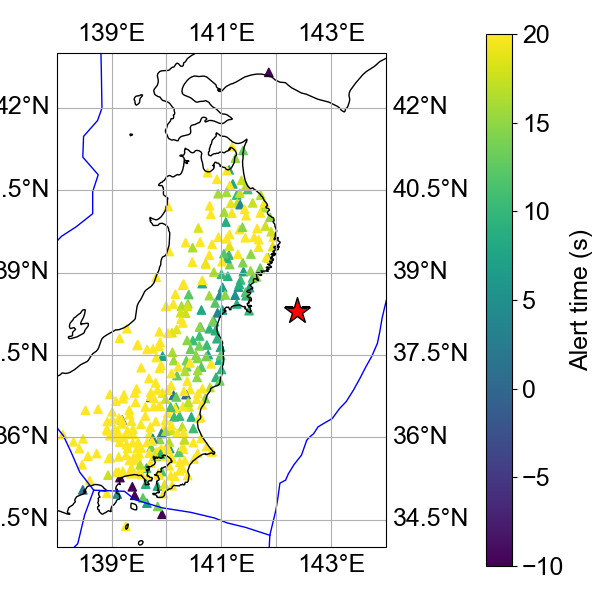

In [97]:
%matplotlib widget

fig = plt.figure(figsize=[6,6],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines()

c = ax.scatter(mmi_df1.longitude,mmi_df1.latitude,c=mmi_df1.alert_time,marker='^',vmin=-10,vmax=20)
plt.colorbar(c,label='Alert time (s)')

ax.plot(eq_lon,eq_lat,'r*',markersize=20,markeredgecolor='k')

# Plot tectonic plate boundaries from local file
for feature in plate_boundaries['features']:
    coords = feature['geometry']['coordinates']
    if feature['geometry']['type'] == 'LineString':
        lons, lats = zip(*coords)
        ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
    elif feature['geometry']['type'] == 'MultiLineString':
        for line in coords:
            lons, lats = zip(*line)
            ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
ax.set_xlim([138,144])
ax.set_ylim([34,43])
gl = ax.gridlines(draw_labels=True) 

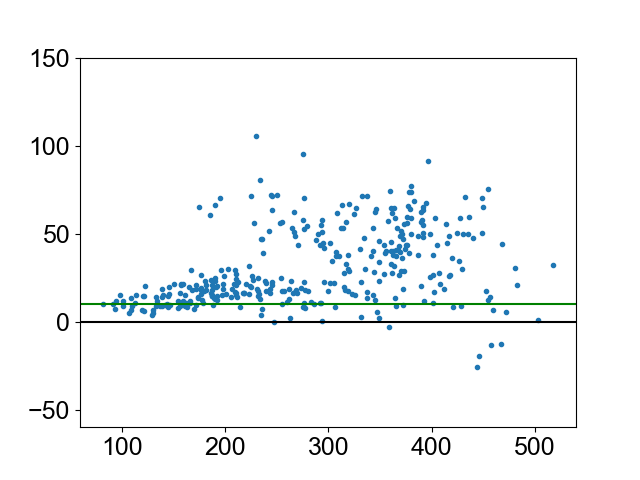

In [98]:
fig,ax = plt.subplots(1)
ax.plot(mmi_df1.hypo_dist,mmi_df1.alert_time,'.')
ax.set_ylim(-60,150)
ax.axhline(0,color='k')
ax.axhline(10,color='g')